# Registrando as execuções (_runs_) do projeto

## 1 Dependências e configuração

In [1]:
import sys
sys.path.insert(0, "../src")

from support_module import RANDOM_STATE, generate_credit_risk_base, data_preprocess
import mlflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, RocCurveDisplay
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
df = generate_credit_risk_base(6000)
print(df.shape)
df.head()

(6000, 9)


,idade,renda_mensal,tempo_emprego_anos,score_interno,valor_solicitado,num_parcelas,tipo_renda,possui_restricao,inadimplente
0,25,5630.15,0.3,501,5234.99,24,CLT,nao,0
1,56,2491.57,9.6,593,8264.73,18,CLT,sim,0
2,50,1020.17,1.0,695,12435.70,12,CLT,nao,0
3,41,1580.32,11.7,527,14883.12,48,CLT,nao,0
4,41,6635.91,2.7,618,12856.88,24,CLT,nao,0


In [3]:
# seleciona features
TARGET   = "inadimplente"
FEATURES = [c for c in df.columns if c != TARGET]
x        = df[FEATURES]
y        = df[TARGET]

# separa colunas numericas e categoricas
num_cols = df[FEATURES].select_dtypes(include='number').columns
cat_cols = [f for f in FEATURES if f not in num_cols]

# separa dados de treino e teste, seguindo proporcao de casos positivos e negativos do target
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

# pipeline de transformacao dos daddos
preprocess = data_preprocess()

x_train.shape, x_test.shape

((4500, 8), (1500, 8))

## 2 Registrando a primeira _run_ do projeto

Vamos começar configurando o _tracking_, definindo onde os metadados (parâmetros e métricas) dos experimentos devem ficar armazenados, e logo em seguida já definimos um experimento para o modelo _baseline_.

Ao rodar o comando `mlflow.set_tracking_uri("sqlite:///../mlflow.db")` fazemos a ligação do nosso código com o banco de dados que já existe (se ainda não existir, então cria um) para armazenar os metadados das _runs_ (execuções). Esses metadados armazenados incluem: nomes das execuções, parâmetros, métricas, _tags_ e os caminhos onde os artefatos são salvos.

In [4]:
# define o tracking com um banco de dados relacional
mlflow.set_tracking_uri("sqlite:///../mlflow.db") 

# cria experimento e define local para armazenar artefatos
mlflow.create_experiment(name="risco_credito_baseline", artifact_location="/home/bruno/estudos/data-science-portifolio/mlflow/mlruns/0/")

# define experimento criado como ativo
mlflow.set_experiment("risco_credito_baseline")

2026/10/12 16:09:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/12 16:09:21 INFO mlflow.store.db.utils: Updating database tables


<Experiment: artifact_location='/home/bruno/estudos/data-science-portifolio/mlflow/mlruns/0/', creation_time=1791832169341, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791832169341, lifecycle_stage='active', name='risco_credito_baseline', tags={}, trace_location=None, workspace='default'>

Se não quiséssemos especificar o local de armazenamento dos artefatos, poderíamos apenas rodar `mlflow.set_experiment()`.

Com isso já estamos prontos para registrar a primeira execução do projeto. Faremos isso usando o gerenciador de contexto `with`, em que vamos iniciar uma _run_ rastreada, e dessa forma, tudo que for gerado dentro desse bloco ficará associado a essa _run_ registrada.

In [5]:
# define classificador
clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)

# inicia run rastreada pelo gerenciador de contexto, garantindo que a run seja finalizada ao final
with mlflow.start_run(run_name="baseline_regressao_logistica") as run:

    model_pipe = Pipeline(
        steps=[
            ("prep", preprocess),
            ("model", clf),
        ]
    )

    # treina o modelo e faz previsoes no conjunto de teste
    model_pipe.fit(x_train, y_train)
    y_proba = model_pipe.predict_proba(x_test)[:, 1]
    y_pred  = model_pipe.predict(x_test)

    # calcula principal metrica de desempenho
    roc_auc_teste = roc_auc_score(y_test, y_proba)

    # validacao cruzada
    cv     = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(model_pipe, x_train, y_train, cv=cv, scoring="roc_auc")

    report = classification_report(y_test, 
                                   y_pred, 
                                   target_names=["adimplente", "inadimplente"],
                                   output_dict=True)

    # registra parametros utilizados no classificador
    mlflow.log_params({
                    "modelo":       "LogisticRegression",
                    "max_iter":     2000,
                    "class_weight": "balanced",
                    "test_size":    0.25,
                    "random_state": RANDOM_STATE,
                    "n_amostras":   len(df),
                    "n_features":   x.shape[1],
                    "cv_folds":     5,
                    "scoring_cv":   "roc_auc",
                    })
    
    # registra metricas do modelo
    mlflow.log_metrics({
                    "roc_auc_teste":          float(roc_auc_teste),
                    "roc_auc_cv_media":       float(scores.mean()),
                    "roc_auc_cv_desvio":      float(scores.std()),
                    "accuracy_teste":         float(report["accuracy"]),
                    "precision_inadimplente": float(report["inadimplente"]["precision"]),
                    "recall_inadimplente":    float(report["inadimplente"]["recall"]),
                    "f1_inadimplente":        float(report["inadimplente"]["f1-score"]),
                    })

    print("Run ID:", run.info.run_id)
    print("ROC-AUC teste:", round(roc_auc_teste, 4))
    print("ROC-AUC CV:", f"{scores.mean():.4f} ± {scores.std():.4f}")

Run ID: 007f1dc71aeb43d7a9642484aaf127c1
ROC-AUC teste: 0.9036
ROC-AUC CV: 0.9045 ± 0.0128


Após essa execução rastreada, podemos acessar a _user interface_ do MLFlow para consultá-la. Para isso rodamos o comando abaixo no terminal

```terminal
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

e depois acessamos o endereço [http://127.0.0.1:5000](http://127.0.0.1:5000).

## 3 Logging manual de uma _run_

Quando trabalhamos em equipe devemos sempre nos perguntar se "outra pessoa é capaz de enteder o que fizemos". Para que isso seja possível, precisamos deixar claro:

- que dados foram usados,
- quais parâmetros o modelo usa e
- quais métricas foram obtidas.

Basicamente precisamos mostrar **o que uma execução tem de relevante** em relação a outras.

Além disso, precisamos garantir que os registros são consistentes com uma convenção, para que possam ser comparáveis. O registro preciso dessas informações é o que transforma uma execução em um registro documentado e auditável.

O MLFlow possui dois modos de registros dos logs: autolog (automático e rápido) e logging manual (mais trabalhoso, mas também mais indicado quando um controle granular é necessário). Agora vamos tratar do _logging manual_.

Aqui estarmos usando o gerenciador de contexto `with`, que encerra a _run_ automáticamente, então não precisamos nos preocupar com "_runs_ abertas". Mas se não fosse esse o caso, poderiamos implementar uma medida de seguraça para evitar registrar informações em alguma execução (_run_) que ficou aberta. Fariamos isso colocando o código abaixo logo antes de iniciar uma nova _run_:

```python
if mlflow.active_run() is not None:
    mlflow.end_run()
```

De modo a enriquecer o log, vamos dar um nome mais explicativo para a _run_, iremos registrar mais informações nos parâmetros (qual é o classificador, quais os hiperparâmetros, como foi feito o split e o pré-processamento) e também nas métricas.

In [6]:
# esse nome indica que se trata da primeira versao de um baseline de Logistic Regression com log manual
RUN_NAME = "baseline_logistic_regression_manual_v1"

with mlflow.start_run(run_name=RUN_NAME) as run:

    # treina o modelo e faz previsoes no conjunto de teste
    model_pipe.fit(x_train, y_train)
    y_proba = model_pipe.predict_proba(x_test)[:, 1]
    y_pred  = model_pipe.predict(x_test)

    # calcula principal metrica de desempenho
    roc_auc_teste = roc_auc_score(y_test, y_proba)

    # validacao cruzada
    cv     = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        model_pipe,
        x_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
    )

    # calcula mais metricas: matriz de confusao
    cm             = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    # descreve o que foi configurado
    params = {
        "modelo":                 "LogisticRegression",
        "max_iter":               2000,
        "class_weight":           "balanced",
        "pipeline":               "preprocessamento_sklearn",
        "numeric_imputer":        "median",
        "numeric_scaler":         "StandardScaler",
        "categorical_imputer":    "most_frequent",
        "categorical_encoder":    "OneHotEncoder",
        "handle_unknown":         "ignore",
        "test_size":              0.25,
        "random_state":           RANDOM_STATE,
        "cv_folds":               5,
        "cv_scoring":             "roc_auc",
        "n_amostras":             len(df),
        "n_features":             x.shape[1],
        "n_train":                len(x_train),
        "n_test":                 len(x_test),
        "target":                 TARGET,
    }

    # descreve o que foi obtido como resultado do modelo
    metrics = {
        "roc_auc_teste":          float(roc_auc_teste),
        "roc_auc_cv_media":       float(scores.mean()),
        "roc_auc_cv_desvio":      float(scores.std()),
        "accuracy_teste":         float(accuracy_score(y_test, y_pred)),
        "precision_inadimplente": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall_inadimplente":    float(recall_score(y_test, y_pred, zero_division=0)),
        "f1_inadimplente":        float(f1_score(y_test, y_pred, zero_division=0)),
        "tn":                     int(tn),
        "fp":                     int(fp),
        "fn":                     int(fn),
        "tp":                     int(tp),
    }

    mlflow.log_params(params)
    mlflow.log_metrics(metrics)

    print("Run ID:", run.info.run_id)
    print("ROC-AUC teste:", round(roc_auc_teste, 4))
    print("ROC-AUC CV:", f"{scores.mean():.4f} ± {scores.std():.4f}")


Run ID: 77816672e8854ce2bd10cec5a62da7fd
ROC-AUC teste: 0.9036
ROC-AUC CV: 0.9045 ± 0.0128


## 4 Adicionando _tags_ e artefatos a uma _run_

Agora vamos adicionar mais duas camadas de documentação para ajudar no entendimento e compreensão das _runs_: as _tags_ e os artefatos. Em projetos colaborativos são recursos muito importantes, pois reduzem a dependência da memória de quem treinou o modelo.

As **_tags_** ajudam a entender não apenas o número final, mas o contexto da execução. Com elas podemos destacar informações como a versão do dataset utilizado, o objetivo do teste, qual o tipo do modelo e o classificador utilizado. Além disso, as _tags_ também permitem filtrar e organizar as execuções.

Já os **artefatos** são as evidências associados à execução. Eles podem ser imagens, relatórios, tabelas, arquivos de texto ou qualquer outro material que ajude a auditar o experimento.

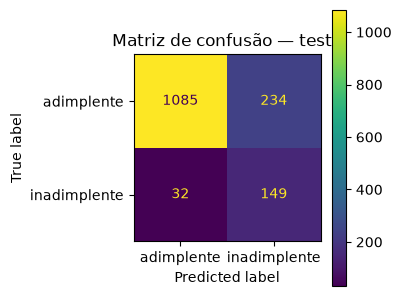

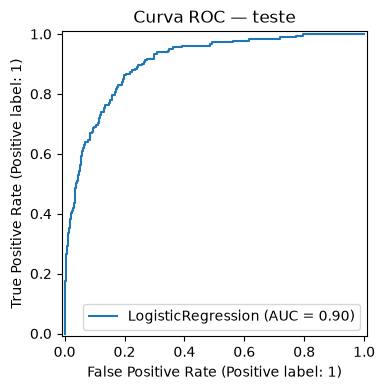

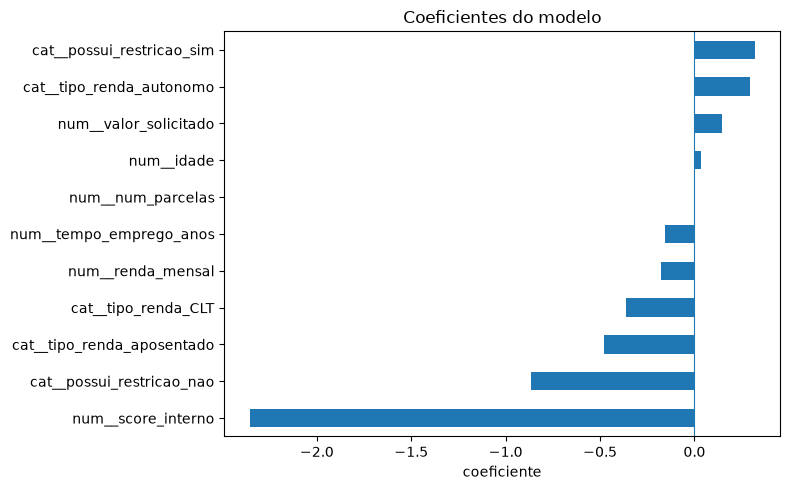

Run ID: 38be829639a64a08b442280795bf2098
ROC-AUC teste: 0.9036
ROC-AUC CV: 0.9045 ± 0.0128
Artefatos armazenados em: /home/bruno/estudos/data-science-portifolio/mlflow/mlruns/0/38be829639a64a08b442280795bf2098/artifacts


In [7]:
# esse nome indica que se trata versao de um baseline de Logistic Regression com log manual e adicao de tags e artefatos
RUN_NAME = "baseline_logistic_regression_manual_v2_tags_artefatos"

with mlflow.start_run(run_name=RUN_NAME) as run:
    
    # treina o modelo e faz previsoes no conjunto de teste
    model_pipe.fit(x_train, y_train)
    y_proba = model_pipe.predict_proba(x_test)[:, 1]
    y_pred  = model_pipe.predict(x_test)

    # calcula principal metrica de desempenho
    roc_auc_teste = roc_auc_score(y_test, y_proba)

    # validacao cruzada
    cv     = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(
        model_pipe,
        x_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
    )

    # calcula mais metricas: matriz de confusao
    cm             = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()


    # descreve o que foi configurado
    params = {
        "modelo":              "LogisticRegression",
        "max_iter":            2000,
        "class_weight":        "balanced",
        "pipeline":            "preprocessamento_sklearn",
        "numeric_imputer":     "median",
        "numeric_scaler":      "StandardScaler",
        "categorical_imputer": "most_frequent",
        "categorical_encoder": "OneHotEncoder",
        "handle_unknown":      "ignore",
        "test_size":           0.25,
        "random_state":        RANDOM_STATE,
        "cv_folds":            5,
        "cv_scoring":          "roc_auc",
        "n_amostras":          len(df),
        "n_features":          x.shape[1],
        "n_train":             len(x_train),
        "n_test":              len(x_test),
        "target":              TARGET,
    }
    mlflow.log_params(params)


    # descreve o que foi obtido como resultado do modelo
    metrics = {
        "roc_auc_teste":          float(roc_auc_teste),
        "roc_auc_cv_media":       float(scores.mean()),
        "roc_auc_cv_desvio":      float(scores.std()),
        "accuracy_teste":         float(accuracy_score(y_test, y_pred)),
        "precision_inadimplente": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall_inadimplente":    float(recall_score(y_test, y_pred, zero_division=0)),
        "f1_inadimplente":        float(f1_score(y_test, y_pred, zero_division=0)),
        "tn":                     int(tn),
        "fp":                     int(fp),
        "fn":                     int(fn),
        "tp":                     int(tp),
    }
    mlflow.log_metrics(metrics)
    
    
    # adiciona tags para melhor rastreabilidade da run
    tags = {
        "project":         "risco_credito",
        "dataset_version": "synthetic_credit_v1",
        "model_family":    "linear_model",
        "task":            "binary_classification",
        "target":          "inadimplente",
        "tracking_type":   "manual",
        "run_purpose":     "baseline_with_manual_artifacts",
    }
    mlflow.set_tags(tags)


    # gera o relatorio de classificacao como artefato
    report_text = classification_report(y_test, y_pred, target_names=["adimplente", "inadimplente"])
    mlflow.log_text(report_text, "reports/classification_report.txt")
    report_dict = classification_report(y_test, y_pred, target_names=["adimplente", "inadimplente"], output_dict=True)
    mlflow.log_dict(report_dict, "reports/classification_report.json")


    # registra matriz de confusao como imagem
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["adimplente", "inadimplente"], ax=ax)
    ax.set_title("Matriz de confusão — teste")
    plt.tight_layout()

    mlflow.log_figure(fig, "plots/matriz_confusao.png")
    plt.show()
    plt.close(fig)


    # registra curva ROC
    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_predictions(y_test, y_proba, name="LogisticRegression", ax=ax)
    ax.set_title("Curva ROC — teste")
    plt.tight_layout()

    mlflow.log_figure(fig, "plots/curva_roc.png")
    plt.show()
    plt.close(fig)


    # registra coeficientes do modelo: como tabela e figura
    prep          = model_pipe.named_steps['prep']
    model         = model_pipe.named_steps['model']
    feature_names = prep.get_feature_names_out()
    coef_df       = (
        pd.DataFrame({
            "feature": feature_names,
            "coeficiente": model.coef_.ravel(),
        })
        .sort_values("coeficiente")
        .reset_index(drop=True)
    )
    mlflow.log_table(coef_df, "tables/coeficientes_modelo.json")

    fig, ax = plt.subplots(figsize=(8, 5))
    coef_df.plot(kind="barh", x="feature", y="coeficiente", legend=False, ax=ax)
    ax.axvline(0, linewidth=0.8)
    ax.set_title("Coeficientes do modelo")
    ax.set_xlabel("coeficiente")
    ax.set_ylabel("")
    plt.tight_layout()

    mlflow.log_figure(fig, "plots/coeficientes_modelo.png")
    plt.show()
    plt.close(fig)
    

    # registrando perfil do dataset
    dataset_profile = {
        "dataset_version":     "synthetic_credit_v1",
        "n_amostras":          int(len(df)),
        "n_colunas":           int(df.shape[1]),
        "target":              TARGET,
        "features":            list(FEATURES),
        "num_cols":            num_cols,
        "cat_cols":            cat_cols,
        "target_distribution": df[TARGET].value_counts(normalize=True).round(4).to_dict(),
        "dtypes":              df.dtypes.astype(str).to_dict()
    }
    mlflow.log_dict(dataset_profile, "data/dataset_profile.json")


    # registrando um resumo executivo da run
    run_summary = (
        f"# Resumo da run\n"
        f"\n"
        f"## Contexto\n"
        f"\n"
        f"Projeto: risco de crédito \n"
        f"Objetivo da run: baseline com tracking manual enriquecido \n"
        f"Modelo: Regressão Logística \n"
        f"Target: {TARGET}\n"
        f"\n"
        f"## Dados\n"
        f"\n"
        f"- Amostras totais: {len(df)}\n"
        f"- Treino: {len(x_train)}\n"
        f"- Teste: {len(x_test)}\n"
        f"- Features: {x.shape[1]}\n"
        f"- Dataset version: synthetic_credit_v1\n"
        f"\n"
        f"## Principais métricas\n"
        f"\n"
        f"- ROC-AUC teste: {roc_auc_teste:.4f}\n"
        f"- ROC-AUC CV média: {scores.mean():.4f}\n"
        f"- ROC-AUC CV desvio: {scores.std():.4f}\n"
        f"- Precision inadimplente: {metrics["precision_inadimplente"]:.4f}\n"
        f"- Recall inadimplente: {metrics["recall_inadimplente"]:.4f}\n"
        f"- F1 inadimplente: {metrics["f1_inadimplente"]:.4f}\n"
        f"\n"
        f"## Leitura inicial\n"
        f"\n"
        f"O modelo funciona como baseline rastreável. \n"
        f"A ROC-AUC indica boa capacidade de ordenação dos casos por risco. \n"
        f"A análise de precision e recall da classe inadimplente deve ser usada para discutir trade-offs de negócio em aulas futuras."
    )
    mlflow.log_text(run_summary, "reports/run_summary.md")


    print("Run ID:", run.info.run_id)
    print("ROC-AUC teste:", round(roc_auc_teste, 4))
    print("ROC-AUC CV:", f"{scores.mean():.4f} ± {scores.std():.4f}")
    print("Artefatos armazenados em:", mlflow.get_artifact_uri())


Para registrar as tags e artefatos da execução (_run_), usamos os métodos:

- `mlflow.set_tags()`: adiciona _tags_ que ajudam a organizar, filtrar e categorizar as execuções dentro do experimento.
- `mlflow.log_text()`: utilizado para salvar arquivos de texto simples, ideal para documentações que precisam ser facilmente lidas por humanos ou interpretadas por sistemas que leem texto;
- `mlflow.log_dict()`: serve para salvar objetos estruturados, como dicionários do Python, no formato JSON, excelente de manter dados estruturados que descrevem a execução;
- `mlflow.log_figure()`: específico para registrar elementos visuais gerados pelo Matplotlib ou outras bibliotecas de visualização. O MLflow a armazena como um arquivo de imagem, permitindo a visualização do comportamento do modelo diretamente na interface de artefatos; e
- `mlflow.log_table()`: registra estruturas de dados tabulares como DataFrames, geralmente em formato JSON. Permite registrar os dados brutos que geraram a visualização, possibilitando uma auditoria mais precisa.

Os artefatos da execução ficam armazenados em um diretório específico daquela execução que está rodando no momento. Então, quando passamos um _path_ como argumento desses métodos, estamos definindo a organização de subpastas e arquivos dentro da execução. Esse caminho é o nome (e o local) que aparecerá na árvore de arquivos da interface do usuário, por isso é uma boa prática manter nomes descritivos e consistentes.

O SQLite funciona como um índice ou um "mapa" que diz ao MLflow: "A execução X possui uma imagem em tal local".

Se não for especificado ao definir um experimento ("agragdor de execuções"), o MLFlow vai criar uma pasta chamada `mlruns/` no CWD (_current working directory_). Caso quiséssemos especificar outro local para armazenar os artefatos do experimento, o faríamos no momento que criamos esse novo experimento:

In [8]:
experiment_id_new = mlflow.create_experiment(
    name="risco_credito_baseline_outro_local_artefatos",
    artifact_location="/home/bruno/estudos/data-science-portifolio/mlflow/z_mlruns/"
)
mlflow.set_experiment(experiment_id=experiment_id_new)

print("ID do novo experimento criado:", experiment_id_new)

ID do novo experimento criado: 2


In [9]:
# roda novamente a mesma run, mas agora com o novo experimento e local de artefatos, apenas para gerar os artefatos no novo local
RUN_NAME = "baseline_logistic_regression_manual_v2_tags_artefatos_outro_local"

# inicia run rastreada pelo gerenciador de contexto, garantindo que a run seja finalizada ao final
with mlflow.start_run(run_name=RUN_NAME) as run:

    model_pipe = Pipeline(
        steps=[
            ("prep", preprocess),
            ("model", clf),
        ]
    )

    # treina o modelo e faz previsoes no conjunto de teste
    model_pipe.fit(x_train, y_train)
    y_proba = model_pipe.predict_proba(x_test)[:, 1]
    y_pred  = model_pipe.predict(x_test)

    # calcula principal metrica de desempenho
    roc_auc_teste = roc_auc_score(y_test, y_proba)

    # validacao cruzada
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    scores = cross_val_score(
        model_pipe, x_train, y_train,
        cv=cv, scoring="roc_auc"
    )

    report = classification_report(y_test, 
                                   y_pred, 
                                   target_names=["adimplente", "inadimplente"],
                                   output_dict=True)

    # registra parametros utilizados no classificador
    mlflow.log_params({
                    "modelo":       "LogisticRegression",
                    "max_iter":     2000,
                    "class_weight": "balanced",
                    "test_size":    0.25,
                    "random_state": RANDOM_STATE,
                    "n_amostras":   len(df),
                    "n_features":   x.shape[1],
                    "cv_folds":     5,
                    "scoring_cv":   "roc_auc",
                    })
    
    # registra metricas do modelo
    mlflow.log_metrics({
                    "roc_auc_teste":          float(roc_auc_teste),
                    "roc_auc_cv_media":       float(scores.mean()),
                    "roc_auc_cv_desvio":      float(scores.std()),
                    "accuracy_teste":         float(report["accuracy"]),
                    "precision_inadimplente": float(report["inadimplente"]["precision"]),
                    "recall_inadimplente":    float(report["inadimplente"]["recall"]),
                    "f1_inadimplente":        float(report["inadimplente"]["f1-score"]),
                    })
    
    # registrando um resumo executivo da run
    mlflow.log_text((
        f"# Resumo da run\n"
        + f"\n"
        + f"## Contexto\n"
        + f"\n"
        + f"Projeto: risco de crédito \n"
        + f"Objetivo da run: Armazenar artefatos e tags em local diferente \n"
        + f"Modelo: Regressão Logística \n"
        + f"Target: {TARGET}\n"
        + f"\n"
        + f"## Dados\n"
        + f"\n"
        + f"- Amostras totais: {len(df)}\n"
        + f"- Treino: {len(x_train)}\n"
        + f"- Teste: {len(x_test)}\n"
        + f"- Features: {x.shape[1]}\n"
        + f"- Dataset version: synthetic_credit_v1\n"
    ), "reports/run_summary.md")

    print("Run ID:", run.info.run_id)
    print("ROC-AUC teste:", round(roc_auc_teste, 4))
    print("ROC-AUC CV:", f"{scores.mean():.4f} ± {scores.std():.4f}")
    print("Artefatos armazenados em:", mlflow.get_artifact_uri())

Run ID: 9e1921dded394a7aa01e4be34984efbc
ROC-AUC teste: 0.9036
ROC-AUC CV: 0.9045 ± 0.0128
Artefatos armazenados em: /home/bruno/estudos/data-science-portifolio/mlflow/z_mlruns/9e1921dded394a7aa01e4be34984efbc/artifacts
